# Modelo Wright-Fisher

### Manual de instalación de python en un ambiente de conda

```bash
## Crear ambiente de conda con python
conda create -n biocompu python=3.13 -y
## Activar ambiente
conda activate biocompu
## Instalar paqueterias para numpy y para usar jupyter notebook en VS code
conda install -c conda-forge numpy jupyter notebook matplotlib scipy ipykernel -y
## Instalar kernel del ambiente en VS code
python -m ipykernel install --user --name biocompu --display-name "Python (biocompu)"
```

In [ ]:
import numpy as np

### Reglas

- El numero de individuos por generación permanece constante y se denomina como $N$

- Cada individuo de la siguiente generacion proviene de un individuo de la generacion pasada.

- La seleccion de padres se realiza siguiendo una distribución uniforme. Esto genera una distribución binomial en los hijos.

- Las generaciones no son sobrelapantes



### Muestreo Binomial

* **Extracción de gametos:**

En cada generación $t$, la formación de la siguiente generación se modela como un muestreo aleatorio con reemplazo de $2N$ alelos.

* **Paso por `np.random.binomial()`:**

NumPy calcula en paralelo el número de copias del alelo mutante $k_{t+1}$ para **todas las réplicas simultáneamente** según la distribución binomial.
$k_{t+1} \sim \text{Binomial}(2N, p_t)$

Por lo tanto si dividimos la frequencia del alelo $A$ entre el numero de alelos totales, nos dará como resultado la probabilidad de encontrarnos con el alelo $A$ en la siguiente generación
$p_{t+1} = \frac{\text{Binomial}(2N, p_t)}{2N}$.


### 3. Actualización de Frecuencias

* **Broadcasting y normalización:**

El vector de alelos muestreados $k_{t+1}$ se divide elemento a elemento entre el escalar $2N$ (`alelos / (2*N)`) para obtener las nuevas frecuencias $p_{t+1}$.

* **Registro en la matriz de historial:**

Se almacena el vector de frecuencias de la generación actual en la fila correspondiente de la matriz 2D (`historial[t] = p`).


In [ ]:
def simular_wright_fisher(N_ind, p0=0.5, gens=150, reps=100):
    n_alelos = 2 * N_ind
    historial = np.zeros((gens, reps))
    historial[0] = p0
    for t in range(1, gens):
        # Muestreo binomial para calcular p en la siguente generacion
        historial[t] = np.random.binomial(n=n_alelos, p=historial[t-1]) / n_alelos
    return historial

### Uso del modelo W-F: Ejemplo
* **Creación del estado inicial ($t = 0$):**

Se define una frecuencia inicial $p_0$ (por ejemplo, $0.5$) para una población diploide de tamaño $N$ ($2N$ alelos).

In [ ]:
# Ejemplo
N = 5000            # 100 individuos (200 alelos)
p_inicial = 0.6    # Frecuencia inicial 50%
generaciones = 200
replicas = 100

# Ejecución
trayectorias = simular_wright_fisher(N, p_inicial, generaciones, replicas)

In [ ]:
trayectorias

array([[0.6   , 0.6   , 0.6   , ..., 0.6   , 0.6   , 0.6   ],
       [0.5964, 0.6002, 0.6023, ..., 0.5981, 0.6038, 0.5975],
       [0.5985, 0.6048, 0.603 , ..., 0.602 , 0.6053, 0.5992],
       ...,
       [0.6405, 0.605 , 0.4923, ..., 0.4812, 0.5705, 0.6157],
       [0.6322, 0.6083, 0.4987, ..., 0.4747, 0.5672, 0.6197],
       [0.6346, 0.6169, 0.5025, ..., 0.474 , 0.5723, 0.6135]],
      shape=(200, 100))

In [ ]:
# Frecuencias en la última generación
frecuencias_finales = trayectorias[-1, :]

# Cuántas poblaciones fijaron el alelo (frecuencia == 1.0)
fijados = np.sum(frecuencias_finales == 1.0)

# Cuántas poblaciones perdieron el alelo (frecuencia == 0.0)
extinguidos = np.sum(frecuencias_finales == 0.0)

print(f"Poblaciones donde A se fijó: {fijados}/{replicas}")
print(f"Poblaciones donde A se extinguió: {extinguidos}/{replicas}")

Poblaciones donde A se fijó: 0/100
Poblaciones donde A se extinguió: 0/100



### Conclusiones

* **Fluctuación por deriva genética:**
Al no haber selección, mutación ni migración, los cambios en las frecuencias $p$ son guiados únicamente por el azar del muestreo.

* **Divergencia entre poblaciones:**
Aunque la frecuencia promedio de todas las réplicas ($\bar{p}$) se mantiene cercana a $p_0$, las trayectorias individuales se separan.

* **Destino final (Fijación o Extinción):**
A largo plazo, las frecuencias convergen hacia los límites superior o inferior: $p = 1.0$ (el alelo se fijó) o $p = 0.0$ (el alelo se extinguió).

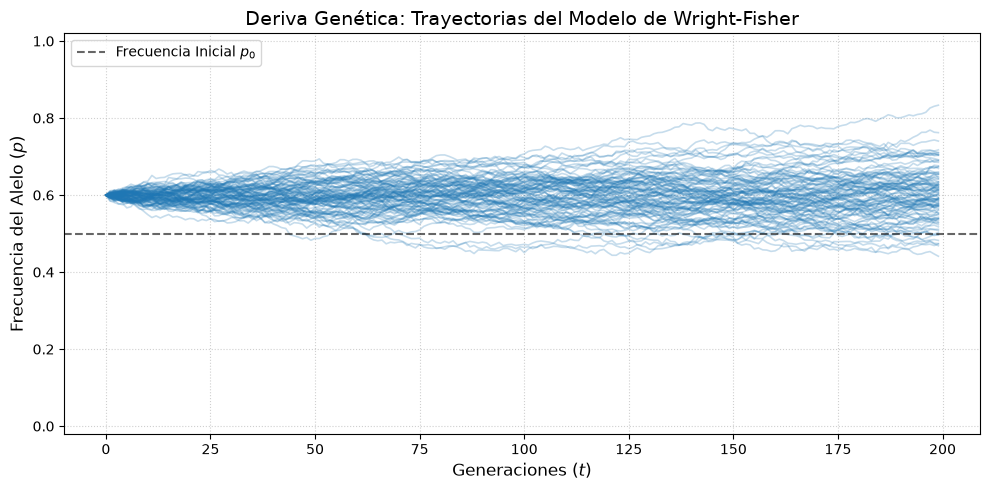

In [ ]:
import matplotlib.pyplot as plt

# Visualización
plt.figure(figsize=(10, 5))

plt.plot(trayectorias, color='tab:blue', alpha=0.25, linewidth=1.2)

# Estructura del gráfico
plt.axhline(y=p0, color='black', linestyle='--', alpha=0.6, label='Frecuencia Inicial $p_0$')
plt.title('Deriva Genética: Trayectorias del Modelo de Wright-Fisher', fontsize=14)
plt.xlabel('Generaciones ($t$)', fontsize=12)
plt.ylabel('Frecuencia del Alelo ($p$)', fontsize=12)
plt.ylim(-0.02, 1.02)
plt.legend(loc='upper left', frameon=True)
plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

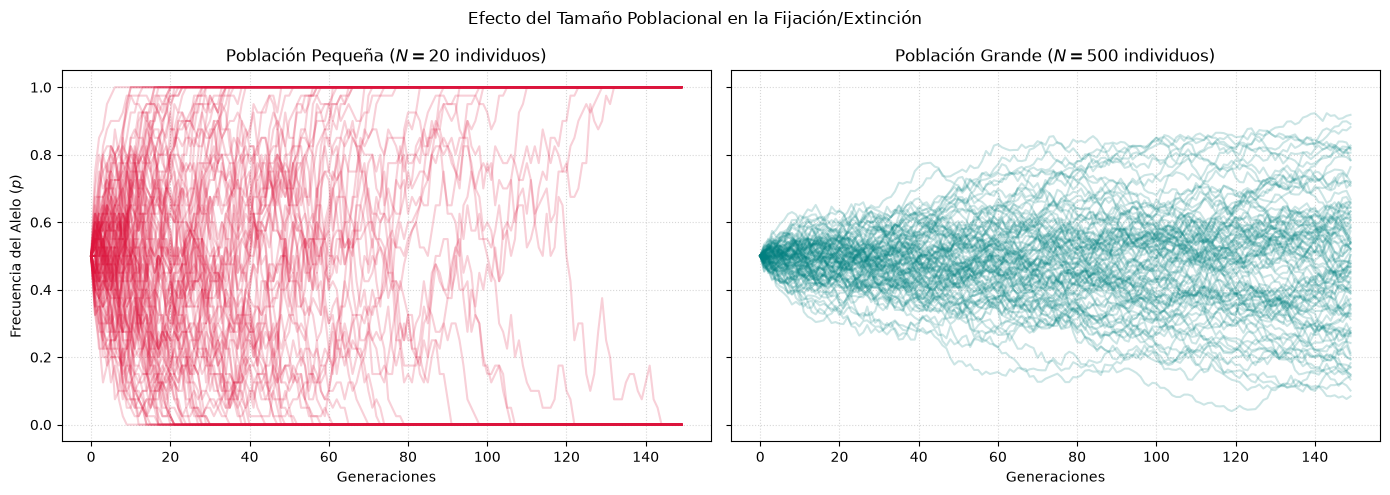

In [ ]:
# Simular para dos tamaños de población
pob_pequeña = simular_wright_fisher(N_ind=20)   # N = 20
pob_grande = simular_wright_fisher(N_ind=500)   # N = 500

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

# Panel 1: Población Pequeña
ax1.plot(pob_pequeña, color='crimson', alpha=0.2)
ax1.set_title('Población Pequeña ($N = 20$ individuos)', fontsize=12)
ax1.set_xlabel('Generaciones')
ax1.set_ylabel('Frecuencia del Alelo ($p$)')
ax1.grid(True, linestyle=':', alpha=0.5)

# Panel 2: Población Grande
ax2.plot(pob_grande, color='teal', alpha=0.2)
ax2.set_title('Población Grande ($N = 500$ individuos)', fontsize=12)
ax2.set_xlabel('Generaciones')
ax2.grid(True, linestyle=':', alpha=0.5)

plt.suptitle('Efecto del Tamaño Poblacional en la Fijación/Extinción')
plt.tight_layout()
plt.show()